In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/drive/MyDrive/file/kc_house_data.csv")
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [3]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True})

In [4]:
print("--- 1. Loading and Inspecting Dataset ---")
file_path = "/content/drive/MyDrive/file/kc_house_data.csv"
df = pd.read_csv(file_path)

--- 1. Loading and Inspecting Dataset ---


In [5]:
print(f"Total Records (Rows): {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nFirst 3 rows:")
display(df.head(3))

Total Records (Rows): 21613
Total Columns: 21

First 3 rows:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062


In [6]:
print("\nDataset Info & Missing Values:")
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print(
    f"Duplicate rows count: {df.duplicated().sum()}"
)


Dataset Info & Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            216

In [7]:
print("\n--- 2. Data Cleaning & Pre-processing ---")


--- 2. Data Cleaning & Pre-processing ---


In [10]:
df["date_parsed"] = pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S")

In [11]:
print(f"Properties with 0 bedrooms: {(df['bedrooms'] == 0).sum()}")
print(f"Properties with 0 bathrooms: {(df['bathrooms'] == 0).sum()}")

Properties with 0 bedrooms: 13
Properties with 0 bathrooms: 10


In [12]:
if 33 in df["bedrooms"].values:
    print("Note: Found the 33-bedroom outlier row. Keeping or flagging as needed.")

Note: Found the 33-bedroom outlier row. Keeping or flagging as needed.


In [13]:
print("\n--- 3. Temporal Feature Engineering ---")


--- 3. Temporal Feature Engineering ---


In [14]:
df["sale_year"] = df["date_parsed"].dt.year
df["sale_month"] = df["date_parsed"].dt.month

In [15]:
df["property_age"] = df["sale_year"] - df["yr_built"]

In [16]:
df["is_renovated"] = df["yr_renovated"].apply(
    lambda x: 1 if x > 0 else 0
)

In [18]:
df["years_since_renovation"] = df.apply(
    lambda row: (
        row["sale_year"] - row["yr_renovated"]
        if row["yr_renovated"] > 0
        else row["property_age"]
    ),
    axis=1,
)
print("\n--- 4. Price per Square Foot Analysis ---")


--- 4. Price per Square Foot Analysis ---


In [19]:
df["sqft_living"] = df["sqft_living"].replace(0, np.nan)
df["sqft_lot"] = df["sqft_lot"].replace(0, np.nan)

In [20]:
df["price_per_sqft_living"] = df["price"] / df["sqft_living"]
df["price_per_sqft_lot"] = df["price"] / df["sqft_lot"]

In [21]:
df.drop(columns=["date_parsed"], inplace=True)

In [22]:
print("\n--- 5. Outlier Detection using IQR Method ---")


--- 5. Outlier Detection using IQR Method ---


In [23]:
def print_iqr_bounds(series, name):
  Q1 = series.quantile(0.25)
  Q3 = series.quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  print(
      f"{name} -> Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f} | Upper Bound:"
      f" {upper_bound:.2f}"
  )

In [25]:
df["date_dt"] = pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S")
df["sale_year"] = df["date_dt"].dt.year
df["sale_month"] = df["date_dt"].dt.month
df["sale_day"] = df["date_dt"].dt.day
df["sale_hour"] = df["date_dt"].dt.hour

df.drop(columns=["date_dt"], inplace=True)
df[["sale_year", "sale_month", "sale_day", "sale_hour"]].head()

,sale_year,sale_month,sale_day,sale_hour
0,2014,10,13,0
1,2014,12,9,0
2,2015,2,25,0
3,2014,12,9,0
4,2015,2,18,0


In [26]:
df["bedrooms"] = df["bedrooms"].replace(0, df["bedrooms"].median())
df["bathrooms"] = df["bathrooms"].replace(0, df["bathrooms"].median())

In [27]:
df["property_age"] = df["sale_year"] - df["yr_built"]

In [28]:
df["is_renovated"] = df["yr_renovated"].apply(lambda x: 1 if x > 0 else 0)

In [29]:
df["years_since_renovation"] = df.apply(
    lambda row: row["sale_year"] - row["yr_renovated"]
    if row["yr_renovated"] > 0
    else row["property_age"],
    axis=1,
)


In [30]:
df["price_per_sqft_living"] = df["price"] / df["sqft_living"]
df["price_per_sqft_lot"] = df["price"] / df["sqft_lot"]

In [32]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["price"] < lower_bound) | (df["price"] > upper_bound)]
print(f"Number of price outliers identified: {len(outliers)}")

Number of price outliers identified: 1146


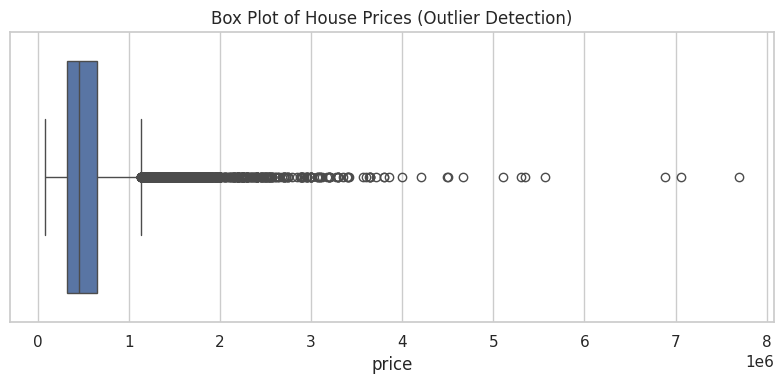

In [33]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["price"])
plt.title("Box Plot of House Prices (Outlier Detection)")
plt.show()